# EDA bộ REES46 (tháng 1/2020)

Mục tiêu: hiểu dữ liệu đủ để **trả lời vì sao từng feature giúp ích** cho mô hình gợi ý.

Mỗi phần gồm: **câu hỏi** → **code** → **cách đọc kết quả và ý nghĩa cho feature**.
Cuối notebook có ô để bạn ghi lại phát hiện của mình.

Dùng **DuckDB**: chạy SQL thẳng lên file, không nạp hết vào RAM.
Lần đầu chuyển CSV sang Parquet (mất vài phút), các lần sau đọc nhanh hơn nhiều.

## 0. Cài đặt
Sửa `CSV_PATH` nếu file nằm chỗ khác. `pip install duckdb matplotlib` nếu chưa có.

In [1]:
import os, time
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "data/2020-Jan.csv"          # hoặc "data/2020-Jan.csv.gz"
PARQUET_PATH = "data/2020-Jan.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")            # giảm nếu máy ít RAM
con.execute("SET temp_directory='data/duckdb_tmp'")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def q(sql):
    """Chạy SQL, trả về DataFrame."""
    return con.sql(sql).df()

## 1. Chuyển CSV sang Parquet (chỉ chạy một lần)

In [3]:
if not os.path.exists(PARQUET_PATH):
    t = time.time()
    con.execute(f"""
        COPY (SELECT * REPLACE (CAST(replace(event_time, ' UTC', '') AS TIMESTAMP) AS event_time)
              FROM read_csv_auto('{CSV_PATH}', types={{'event_time': 'VARCHAR', 'user_session': 'VARCHAR'}}))
        TO '{PARQUET_PATH}' (FORMAT parquet)
    """)
    print(f"Đã tạo {PARQUET_PATH} sau {time.time() - t:.0f}s")
print(f"CSV: {os.path.getsize(CSV_PATH)/1e9:.2f} GB  ->  Parquet: {os.path.getsize(PARQUET_PATH)/1e9:.2f} GB")
con.execute(f"CREATE OR REPLACE VIEW ev AS SELECT * FROM read_parquet('{PARQUET_PATH}')")
q("SELECT * FROM ev LIMIT 5")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Đã tạo 2020-Jan.parquet sau 45s
CSV: 7.78 GB  ->  Parquet: 2.22 GB


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2020-01-01 00:00:00,view,1005073,2232732093077520756,construction.tools.light,samsung,"1,130.0200",519698804,69b5d72f-fd6e-4fed-aa23-1286b2ca89a0
1,2020-01-01 00:00:01,view,1005192,2232732093077520756,construction.tools.light,meizu,205.6700,527767423,7f596032-ccbf-4643-9bad-e36a209512b4
2,2020-01-01 00:00:01,view,100063693,2053013552427434207,apparel.shirt,turtle,136.4300,519046195,d1e2f343-84bb-49bd-b13d-ca0f1ed9910e
3,2020-01-01 00:00:01,view,5100816,2232732103831716449,apparel.shoes,xiaomi,29.9500,518269232,0444841c-38ef-410c-b11f-7b35ea4e5991
4,2020-01-01 00:00:02,view,100014325,2232732103294845523,apparel.shoes.step_ins,intel,167.2000,587748686,31b7d4cf-dfac-4895-9927-90fa3254f860


## 2. Tổng quan
**Câu hỏi:** dữ liệu lớn cỡ nào, từ ngày nào đến ngày nào, mỗi loại sự kiện bao nhiêu?

In [4]:
q("""SELECT COUNT(*) AS so_su_kien, COUNT(DISTINCT user_id) AS so_user,
           COUNT(DISTINCT product_id) AS so_san_pham, COUNT(DISTINCT user_session) AS so_phien,
           MIN(event_time) AS tu, MAX(event_time) AS den FROM ev""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,so_su_kien,so_user,so_san_pham,so_phien,tu,den
0,55967041,4385985,227608,13847854,2020-01-01,2020-01-31 23:59:59


In [5]:
et = q("SELECT event_type, COUNT(*) AS n FROM ev GROUP BY 1 ORDER BY 2 DESC")
et["ty_le"] = et["n"] / et["n"].sum()
et

,event_type,n,ty_le
0,view,52490785,0.9379
1,cart,2641249,0.0472
2,purchase,835007,0.0149


**Đọc kết quả:** lượt xem thường chiếm phần lớn, lượt mua rất ít.
→ Nhãn "mua" **rất thưa**: mô hình phải học từ ít ví dụ dương. Đây là lý do có thể cân nhắc
dùng cả "thêm giỏ" làm nhãn (`--target purchase cart`), và lý do cần các feature từ lượt xem.

## 3. Chất lượng dữ liệu
**Câu hỏi:** thiếu dữ liệu ở đâu, có giá lỗi, có dòng trùng, danh mục có đáng tin không?

In [6]:
q("""SELECT
      AVG(CASE WHEN category_code IS NULL THEN 1 ELSE 0 END) AS thieu_category_code,
      AVG(CASE WHEN brand IS NULL THEN 1 ELSE 0 END)         AS thieu_brand,
      AVG(CASE WHEN user_session IS NULL THEN 1 ELSE 0 END)  AS thieu_session,
      AVG(CASE WHEN price <= 0 THEN 1 ELSE 0 END)            AS gia_khong_hop_le
    FROM ev""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,thieu_category_code,thieu_brand,thieu_session,gia_khong_hop_le
0,0.0901,0.1167,0.0000,0.0031


In [7]:
q("""SELECT COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT event_time, event_type, product_id, user_id FROM ev))
           AS so_dong_trung FROM ev""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,so_dong_trung
0,193451


**Danh mục có bị gán sai không?** Ở 5 dòng đầu, điện thoại Samsung lại nằm trong `construction.tools.light`.
Kiểm tra: mỗi `category_code` có bao nhiêu thương hiệu và giá dao động thế nào.
Danh mục "đèn dụng cụ" mà có Apple, Samsung, giá cả nghìn đô là dấu hiệu gán sai.

In [8]:
q("""SELECT category_code, COUNT(DISTINCT product_id) AS so_sp, COUNT(DISTINCT brand) AS so_brand,
           quantile_cont(price, 0.5) AS gia_trung_vi,
           string_agg(DISTINCT brand, ', ') FILTER (WHERE brand IN ('apple','samsung','xiaomi','huawei')) AS brand_dien_thoai
    FROM ev WHERE category_code IS NOT NULL
    GROUP BY 1 ORDER BY so_sp DESC LIMIT 15""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,category_code,so_sp,so_brand,gia_trung_vi,brand_dien_thoai
0,apparel.shoes,11481,779,76.9600,"samsung, xiaomi, huawei"
1,electronics.clocks,10819,239,165.5100,"huawei, apple, samsung, xiaomi"
2,furniture.kitchen.table,6158,268,34.7200,"xiaomi, samsung, apple"
3,apparel.shirt,5479,363,47.4900,xiaomi
4,sport.ski,5257,176,53.9000,"apple, xiaomi"
5,accessories.bag,4837,382,43.7300,"apple, xiaomi"
6,kids.toys,4706,392,63.5800,"xiaomi, huawei, samsung"
7,computers.desktop,4692,328,60.4900,"xiaomi, apple"
8,sport.bicycle,4683,279,89.8400,"huawei, apple, xiaomi, samsung"
9,apparel.shoes.keds,4036,324,84.9400,"xiaomi, samsung"


In [22]:
# Một sản phẩm có bị gán nhiều danh mục khác nhau theo thời gian không?
q("""SELECT COUNT(*) AS so_sp, AVG(CASE WHEN n_cat > 1 THEN 1 ELSE 0 END) AS ty_le_sp_nhieu_danh_muc
    FROM (SELECT product_id, COUNT(DISTINCT category_id) AS n_cat FROM ev GROUP BY 1)""")

,so_sp,ty_le_sp_nhieu_danh_muc
0,227608,0.0000


**Ý nghĩa cho feature:**
- `brand` thiếu nhiều → `aff_brand` chỉ có ích với phần có thương hiệu (code đã đặt 0 cho brand thiếu).
- `category_code` sai hoặc thiếu → nên dùng `category_id` (mã số, luôn có) cho feature danh mục, đúng như `features.py` đang làm.
  Còn `category_code` chỉ dùng để đọc hiểu.

## 4. Phễu chuyển đổi
**Câu hỏi:** bao nhiêu % lượt xem thành thêm giỏ, thêm giỏ thành mua? Bao nhiêu user từng mua?

In [9]:
q("""WITH u AS (
      SELECT user_id,
             MAX(CASE WHEN event_type='view' THEN 1 ELSE 0 END) AS xem,
             MAX(CASE WHEN event_type='cart' THEN 1 ELSE 0 END) AS gio,
             MAX(CASE WHEN event_type='purchase' THEN 1 ELSE 0 END) AS mua
      FROM ev GROUP BY 1)
    SELECT COUNT(*) AS so_user, AVG(xem) AS co_xem, AVG(gio) AS co_them_gio, AVG(mua) AS co_mua,
           SUM(mua) * 1.0 / NULLIF(SUM(gio), 0) AS user_gio_ra_mua
    FROM u""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,so_user,co_xem,co_them_gio,co_mua,user_gio_ra_mua
0,4385985,0.9995,0.1689,0.0819,0.4848


In [10]:
q("""SELECT SUM(CASE WHEN event_type='cart' THEN 1 ELSE 0 END) * 1.0 / SUM(CASE WHEN event_type='view' THEN 1 ELSE 0 END) AS xem_ra_gio,
           SUM(CASE WHEN event_type='purchase' THEN 1 ELSE 0 END) * 1.0 / SUM(CASE WHEN event_type='view' THEN 1 ELSE 0 END) AS xem_ra_mua
    FROM ev""")

,xem_ra_gio,xem_ra_mua
0,0.0503,0.0159


**Ý nghĩa cho feature:** tỷ lệ chuyển đổi khác nhau rất nhiều giữa các sản phẩm →
`item_conv_rate`, `item_cart_rate` giúp tách món "được xem nhiều" khỏi món "được mua nhiều".
Nếu ít user từng mua → nhiều user sẽ là cold start về mua hàng, phải dựa vào lượt xem.

## 5. Người ta có mua lại món đã xem không? (câu quan trọng nhất cho feature)
**Câu hỏi:** trong các lần mua, bao nhiêu % là món user **đã xem trước đó**, và xem trước bao lâu?
- Nếu tỷ lệ cao → feature lịch sử user × sản phẩm (`ui_views`, `hist_rank`...) sẽ rất mạnh.
- Nếu đa số xem rồi mua **ngay trong vài phút** → lịch sử trước mốc cắt (ngày hôm trước) ít giúp;
  mô hình phải dựa nhiều vào sở thích và độ phổ biến.

In [11]:
r = q("""
    WITH p AS (SELECT user_id, product_id, MIN(event_time) AS t_mua FROM ev WHERE event_type='purchase' GROUP BY 1, 2),
         v AS (SELECT e.user_id, e.product_id, MIN(e.event_time) AS t_xem_dau
               FROM ev e JOIN p USING (user_id, product_id) WHERE e.event_type='view' GROUP BY 1, 2)
    SELECT p.*, v.t_xem_dau, date_diff('minute', v.t_xem_dau, p.t_mua) AS phut_tu_luc_xem
    FROM p LEFT JOIN v USING (user_id, product_id)""")
print(f"Số cặp (user, sản phẩm) có mua: {len(r):,}")
print(f"Đã xem trước khi mua:            {(r['phut_tu_luc_xem'] >= 0).mean():.1%}")
print(f"Xem trước hơn 1 giờ:            {(r['phut_tu_luc_xem'] > 60).mean():.1%}")
print(f"Xem trước hơn 1 ngày:           {(r['phut_tu_luc_xem'] > 1440).mean():.1%}")
r["phut_tu_luc_xem"].describe(percentiles=[.25, .5, .75, .9])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Số cặp (user, sản phẩm) có mua: 620,577
Đã xem trước khi mua:            99.8%
Xem trước hơn 1 giờ:            22.4%
Xem trước hơn 1 ngày:           14.7%


count   617,780.0000
mean      1,511.4335
std       4,860.7160
min     -35,592.0000
25%           1.0000
50%           3.0000
75%          27.0000
90%       4,120.0000
max      44,288.0000
Name: phut_tu_luc_xem, dtype: Float64

- Nhận xét
    - Người dùng sẽ mua các sản phẩm đã xem, và chủ yếu xem rồi mua ngay. Trung vị khoảng 3 phút từ lúc xem tới lúc mua. 75% mua trong 27 phút
    - Chỉ 14,7% xem trước hơn 1 ngày.

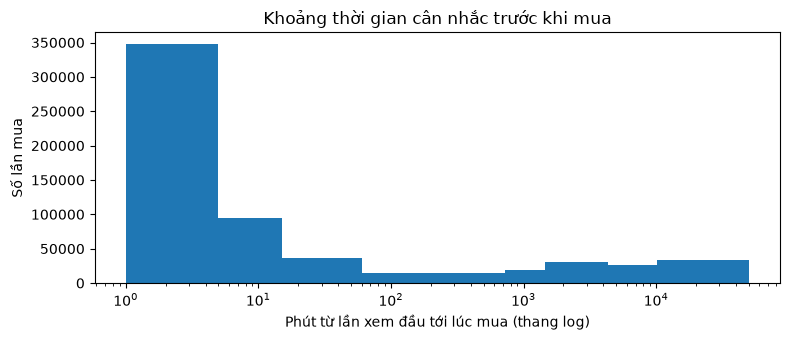

In [12]:
x = r["phut_tu_luc_xem"].dropna().clip(lower=1)
plt.figure(figsize=(8, 3.5))
plt.hist(x, bins=[1, 5, 15, 60, 180, 720, 1440, 4320, 10080, 50000])
plt.xscale("log"); plt.xlabel("Phút từ lần xem đầu tới lúc mua (thang log)"); plt.ylabel("Số lần mua")
plt.title("Khoảng thời gian cân nhắc trước khi mua"); plt.tight_layout(); plt.show()

In [13]:
# Mua lặp lại cùng một món (hàng tiêu hao)
q("""SELECT AVG(CASE WHEN n > 1 THEN 1 ELSE 0 END) AS ty_le_cap_mua_lap_lai
    FROM (SELECT user_id, product_id, COUNT(*) AS n FROM ev WHERE event_type='purchase' GROUP BY 1, 2)""")

,ty_le_cap_mua_lap_lai
0,0.1707


**Ghi lại 3 con số:** % mua món đã xem, % xem trước hơn 1 ngày, % mua lặp lại.
Chúng giải thích trực tiếp vì sao `ui_views`, `ui_days_since_last`, `ui_cart_not_bought`, `ui_purchases` có (hoặc không có) giá trị.

## 6. Độ thưa và đuôi dài
**Câu hỏi:** mỗi user có bao nhiêu sự kiện? Sản phẩm phổ biến chiếm bao nhiêu phần tương tác?

In [14]:
q("""SELECT quantile_cont(n, [0.25, 0.5, 0.75, 0.9, 0.99]) AS phan_vi_su_kien_moi_user, AVG(n) AS trung_binh
    FROM (SELECT user_id, COUNT(*) AS n FROM ev GROUP BY 1)""")

,phan_vi_su_kien_moi_user,trung_binh
0,"[1.0, 3.0, 11.0, 30.0, 138.0]",12.7604


Top 1% sản phẩm chiếm 53.6% tương tác
Top 5% sản phẩm chiếm 75.1% tương tác
Top 20% sản phẩm chiếm 91.7% tương tác


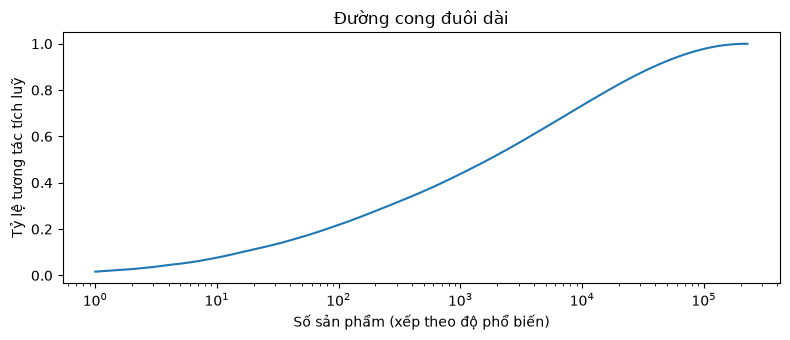

In [15]:
pp = q("""SELECT product_id, COUNT(*) AS n FROM ev GROUP BY 1 ORDER BY 2 DESC""")
pp["tich_luy"] = pp["n"].cumsum() / pp["n"].sum()
for pct in (0.01, 0.05, 0.2):
    k = max(1, int(len(pp) * pct))
    print(f"Top {pct:.0%} sản phẩm chiếm {pp['tich_luy'].iloc[k-1]:.1%} tương tác")
plt.figure(figsize=(8, 3.5)); plt.plot(range(1, len(pp) + 1), pp["tich_luy"])
plt.xscale("log"); plt.xlabel("Số sản phẩm (xếp theo độ phổ biến)"); plt.ylabel("Tỷ lệ tương tác tích luỹ")
plt.title("Đường cong đuôi dài"); plt.tight_layout(); plt.show()

- Nhận xét
    - 1% sản phẩm chiếm 53,6% tương tác.
    - 20% sản phẩm chiếm 91,7% tương tác.
    => popular sẽ là baseline rất khó thắng

**Ý nghĩa:** nếu một nhóm nhỏ sản phẩm chiếm phần lớn tương tác thì baseline Popular sẽ khá mạnh, mô hình phải thắng nó.
Đây cũng là lý do đo thêm **coverage**: mô hình chỉ gợi ý toàn hàng hot thì điểm có thể cao nhưng ít giá trị.

## 7. Theo thời gian
**Câu hỏi:** hành vi có thay đổi theo ngày, theo giờ? Có ngày bất thường (khuyến mãi, Tết) không?

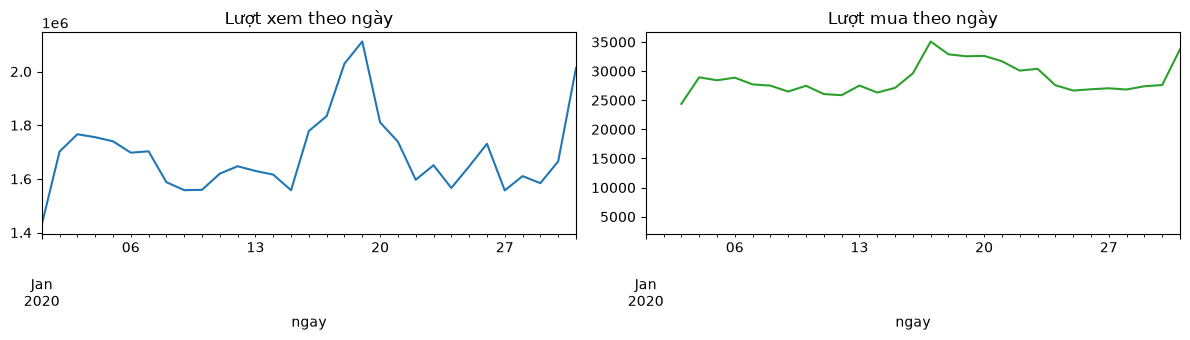

In [16]:
d = q("""SELECT CAST(event_time AS DATE) AS ngay, event_type, COUNT(*) AS n FROM ev GROUP BY 1, 2 ORDER BY 1""")
piv = d.pivot(index="ngay", columns="event_type", values="n")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
piv["view"].plot(ax=ax[0], title="Lượt xem theo ngày")
piv["purchase"].plot(ax=ax[1], title="Lượt mua theo ngày", color="C2")
plt.tight_layout(); plt.show()

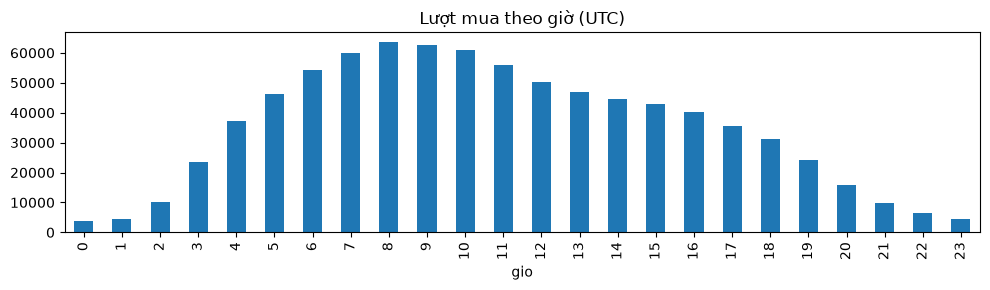

In [19]:
h = q("""SELECT hour(event_time) AS gio, COUNT(*) FILTER (WHERE event_type='purchase') AS mua, COUNT(*) AS tong FROM ev GROUP BY 1 ORDER BY 1""")
h.plot(x="gio", y="mua", kind="bar", figsize=(10, 3), legend=False, title="Lượt mua theo giờ (UTC)"); plt.tight_layout(); plt.show()

**Ý nghĩa:** ngày bất thường có thể làm lệch cửa sổ nhãn. Nếu tuần test rơi vào dịp đặc biệt,
cần ghi chú khi báo cáo. Giờ trong ngày là một ứng viên feature ngữ cảnh.

## 8. Giá
**Câu hỏi:** giá phân bố thế nào? Giá có thay đổi theo thời gian không?

In [17]:
q("""SELECT quantile_cont(price, [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]) AS phan_vi_gia, MAX(price) AS gia_max
    FROM ev WHERE event_type='view'""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,phan_vi_gia,gia_max
0,"[25.71, 64.09, 166.39, 357.54, 746.2, 1801.59]","2,574.0700"


In [18]:
q("""SELECT split_part(category_code, '.', 1) AS danh_muc_cap_1, COUNT(*) AS n,
           quantile_cont(price, 0.5) AS gia_trung_vi
    FROM ev WHERE category_code IS NOT NULL GROUP BY 1 ORDER BY n DESC LIMIT 12""")

,danh_muc_cap_1,n,gia_trung_vi
0,construction,16686966,231.6400
1,appliances,9300429,218.5100
2,apparel,7374702,76.9600
3,electronics,5974373,183.9400
4,sport,3285424,102.6800
5,computers,2714135,158.5600
6,furniture,2635773,71.3000
7,kids,1474542,79.8000
8,accessories,802874,54.0300
9,auto,481254,145.8200


In [20]:
q("""SELECT COUNT(*) AS so_sp,
           AVG(CASE WHEN n_gia > 1 THEN 1 ELSE 0 END) AS ty_le_sp_doi_gia,
           quantile_cont(bien_dong, 0.5) FILTER (WHERE n_gia > 1) AS bien_dong_trung_vi
    FROM (SELECT product_id, COUNT(DISTINCT price) AS n_gia, (MAX(price) - MIN(price)) / MIN(price) AS bien_dong
          FROM ev GROUP BY 1)""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,so_sp,ty_le_sp_doi_gia,bien_dong_trung_vi
0,227608,0.3408,0.1401


**Ý nghĩa:**
- Giá chênh nhau rất lớn giữa các danh mục → cần `item_price_pct_in_cat` (giá tương đối trong danh mục), không chỉ giá tuyệt đối.
- Nếu nhiều sản phẩm đổi giá → feature phải lấy **giá gần nhất trước mốc cắt** (code đã làm vậy),
  và có thể thêm feature mới "giá vừa giảm" (ý tưởng cho bước 5 của bạn).
- Phân bố giá user hay xem là cơ sở để mô phỏng ngân sách.

## 9. Phiên truy cập
**Câu hỏi:** một phiên dài bao nhiêu, xem bao nhiêu món?

In [21]:
q("""SELECT quantile_cont(n_su_kien, [0.5, 0.9]) AS su_kien_moi_phien,
           quantile_cont(n_sp, [0.5, 0.9]) AS san_pham_moi_phien,
           quantile_cont(phut, [0.5, 0.9]) AS phut_moi_phien
    FROM (SELECT user_session, COUNT(*) AS n_su_kien, COUNT(DISTINCT product_id) AS n_sp,
                 date_diff('minute', MIN(event_time), MAX(event_time)) AS phut
          FROM ev GROUP BY 1)""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,su_kien_moi_phien,san_pham_moi_phien,phut_moi_phien
0,"[2.0, 9.0]","[1.0, 6.0]","[0.0, 10.0]"


**Ý nghĩa:** phiên thường xem nhiều món cùng loại → co-visitation (hai món xuất hiện cùng phiên) là nguồn ứng viên tốt.

## 10. Ghi chú phát hiện của bạn
Điền sau khi chạy xong. Mỗi dòng: **phát hiện → ảnh hưởng tới feature hoặc mô hình**.

| # | Phát hiện (có số liệu) | Ảnh hưởng tới feature / mô hình |
| --- | --- | --- |
| 1 | 99,8% lần mua là món đã xem, nhưng trung vị chỉ 3 phút từ lúc xem tới lúc mua; chỉ 14,7% xem trước hơn 1 ngày | Lịch sử trước mốc cắt chỉ bao được ~15–20% món sẽ mua → tầng ứng viên là điểm nghẽn; cần nhiều nguồn ứng viên (phổ biến, danh mục, co-visitation, ALS) |
| 2 | Trung vị 3 sự kiện/user; 25% user chỉ có 1 sự kiện; 8,2% user có mua trong tháng | Đa số user thiếu lịch sử → feature sản phẩm (độ phổ biến, xu hướng, tỷ lệ chuyển đổi) quan trọng hơn feature user |
| 3 | Top 1% sản phẩm chiếm 53,6% tương tác, top 20% chiếm 91,7% | Popular là baseline mạnh; phải báo cáo thêm coverage |
| 4 | category_code bị gán lệch (điện thoại nằm trong "giày", "bàn bếp"); thiếu 9% | Feature danh mục dùng category_id để gom nhóm, không diễn giải tên danh mục |
| 5 | Lượt xem/mua tăng mạnh ngày 16–20/1 | Các cửa sổ train/val/test không đồng đều; nên thêm dữ liệu tháng 12/2019 |
| 6 | Không có remove_from_cart; 17% cặp user–sản phẩm mua lặp lại | ui_removed vô dụng với tháng này; ui_purchases có giá trị |
| 7 | Brand thiếu 11,7% | aff_brand chỉ tác dụng với ~88% sự kiện |

## 11. Cắt mẫu để chạy pipeline
Lấy toàn bộ hành vi của khoảng 5% user (lấy theo **user**, không theo dòng, để giữ nguyên lịch sử từng người).
File này đưa thẳng vào pipeline: `python -m rees46_recsys.train --data 2020-Jan_5pct.parquet`.

In [23]:
SAMPLE_PCT = 5
out = PARQUET_PATH.replace(".parquet", f"_{SAMPLE_PCT}pct.parquet")
con.execute(f"COPY (SELECT * FROM ev WHERE hash(user_id) % 100 < {SAMPLE_PCT}) TO '{out}' (FORMAT parquet)")
s = q(f"SELECT COUNT(*) AS so_su_kien, COUNT(DISTINCT user_id) AS so_user FROM read_parquet('{out}')")
print(out); s

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2020-Jan_5pct.parquet


,so_su_kien,so_user
0,2809407,219769


In [24]:
con.execute("""
COPY (SELECT * REPLACE (CAST(replace(event_time, ' UTC', '') AS TIMESTAMP) AS event_time)
      FROM read_csv_auto('2019-Dec.csv.gz', types={'event_time': 'VARCHAR', 'user_session': 'VARCHAR'})
      WHERE hash(user_id) % 100 < 5)
TO '2019-Dec_5pct.parquet' (FORMAT parquet)
""")
for f in ["2019-Dec_5pct.parquet", "2020-Jan_5pct.parquet"]:
    print(f, q(f"SELECT COUNT(*) AS su_kien, COUNT(DISTINCT user_id) AS user, MIN(event_time) AS tu, MAX(event_time) AS den FROM '{f}'").to_dict("records"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019-Dec_5pct.parquet [{'su_kien': 3362303, 'user': 228837, 'tu': Timestamp('2019-12-01 00:00:17'), 'den': Timestamp('2019-12-31 23:59:58')}]
2020-Jan_5pct.parquet [{'su_kien': 2809407, 'user': 219769, 'tu': Timestamp('2020-01-01 00:00:03'), 'den': Timestamp('2020-01-31 23:59:58')}]
